**Eye-Tracking & Neurocognitive Intelligence | Eye-Tracking Foundations & Signal Analysis | Presented by: Reza Saadatyar (2026)**

**06 | I-VT Threshold Sensitivity and Vendor-Reference Coverage**

![Observed I-VT threshold sensitivity, conditional EyeLink agreement and eligible sample support](../../images/06_detector_sensitivity_and_vendor_reference.svg)

**Objective:** Examine the effects of three fixed I-VT angular-speed thresholds (**20, 30 and 40 dva/s**) on derived gaze classes and conditional agreement with EyeLink parser annotations, without retraining, changing preprocessing or selecting a threshold based on favourable scores.

**Recorded source execution:** GazeBase v2.0, Round 1, Session 1; **10 participants, 40 recordings** and **120 record-by-threshold combinations**. Notebook 06 used the saved prepared samples from Notebook 02. The original Notebook 03 I-VT baseline used **30 dva/s**.

**Observed record-average results (20 / 30 / 40 dva/s):** fixation fractions **28.53% / 61.23% / 78.65%**; unknown fractions **62.24% / 30.57% / 13.78%**; unweighted mean conditional EyeLink agreements **90.97% / 98.13% / 98.78%**.

**Executed reference-support review:** Eligible comparison sample totals were **1,015,044 / 1,888,902 / 2,357,954**, with all 40 records contributing defined agreement at each threshold. Their corresponding eligible-sample-weighted conditional agreements were **94.77% / 98.08% / 98.63%**. The recorded **30-dva/s source-level comparison matches Notebook 03 across all 40 records**.

**Scientific interpretation:** Vendor agreement compares only recognised EyeLink parser codes with evaluable I-VT fixation/saccade assignments. **The eligible denominator changes with threshold.** Neither form of conditional agreement is independently adjudicated accuracy or evidence that 40 dva/s is optimal. The earlier extreme calculated gaze speeds remain a methodological limitation.


**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess

repo_url = "https://github.com/RezaSaadatyar/Eye-Tracking-Neurocognitive-Intelligence.git"
repo_path = Path("/content") / repo_url.rsplit("/", 1)[-1].removesuffix(".git")
if not repo_path.exists():
    subprocess.run(["git", "clone", "-q", repo_url, str(repo_path)], check=True)

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content/Eye-Tracking-Neurocognitive-Intelligence


**01. Imports and Research Environment**

In [2]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("eye_tracking_foundations")

# ----------------- 2. Scientific Computing and Data Analysis -----------------
import numpy as np
import pandas as pd

# ------------------- 3. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure
from core.output_download import download_outputs_from_colab

# ------------------------ 4. Study Research Utilities ------------------------
from core.stage_outputs import ensure_stage_inputs
from gaze_source import read_stage
from eye_events import ivt_labels, label_agreement

# --------------------- 5. Output and Presentation Setup ----------------------
output_dir = root / "eye_tracking_foundations" / "output"
output_dir.mkdir(parents=True, exist_ok=True)
plot_style(
    font_family="DejaVu Sans", title_size=12.5,
    title_weight="normal", label_size=11.5,
    label_weight="normal", tick_size=11,
    legend_size=10, figure_dpi=100, figure_size=(10, 4),
)
print("Current outputs:", output_dir)


Repository up to date.
Current outputs: /content/Eye-Tracking-Neurocognitive-Intelligence/eye_tracking_foundations/output


**02. Recover Prepared Motion and Reference Coverage**

Use the existing `02_preprocessed_samples.csv` from Notebook 02, retaining timestamps, within-run velocity, original record identities and EyeLink parser labels. The original Notebook 03 vendor comparison is read from `03_vendor_agreement.csv`; no original GazeBase CSV is reread.

The committed execution loaded the current 40-record prepared source and the compatible vendor table. This input cell is intentionally **non-visual**: it loads data for the next step rather than duplicating millions of source rows. The executed analysis below confirms 120 record/threshold rows, while Section 04A independently checks the saved 30-dva/s baseline using small CSV files.

Source availability in a Colab runtime depends on the named current output files or their matching Notebook ZIPs. The large prepared CSV need not be reloaded solely to review conditional agreement or regenerate the small summary figure.


In [3]:
# ============ 02. Recover Prepared Motion and Reference Coverage =============

ensure_stage_inputs(output_dir,2,("02_preprocessed_samples.csv",))
ensure_stage_inputs(output_dir,3,("03_vendor_agreement.csv",))
prepared=read_stage(output_dir/"02_preprocessed_samples.csv",
                    ("record_id","participant_id","n","velocity_dva_s","segment_id","lab"))
reference=read_stage(output_dir/"03_vendor_agreement.csv",
                     ("record_id","vendor_coverage_fraction"))


**03. Evaluate Three Prespecified I-VT Thresholds**

Apply the fixed velocity thresholds **20, 30 and 40 dva/s** to each of 40 source recordings, using the same minimum fixation and saccade durations as Notebook 03 (**80 ms** and **6 ms**, respectively). Fractions are calculated over all source samples within each record, with `unknown` retained for invalid, velocity-undefined or insufficient-duration assignments.

For each threshold and record, the saved `06_sensitivity.csv` contains the fixation, saccade and unknown fractions alongside `eligible_samples`, vendor label coverage, the fraction of jointly evaluable samples and conditional sample agreement. The recorded execution produced **120 rows with no reported error**.

This is an exploratory **method sensitivity analysis**, not a trained or tuned classifier comparison. The thresholds are not ranked by agreement because the classified population and eligible comparison denominators change across thresholds. Independent event-level adjudication is unavailable.


In [4]:
# ================ 03. Evaluate Predefined Velocity Thresholds ================

THRESHOLDS=(20.0,30.0,40.0)
rows=[]
for rid,part in prepared.groupby("record_id",sort=True):
    part=part.sort_values("sample_index").reset_index(drop=True)
    for threshold in THRESHOLDS:
        pred=ivt_labels(part,threshold_dva_s=threshold)
        agreement=label_agreement(part,pred)
        rows.append({
            "record_id":rid, "participant_id":str(part.participant_id.iloc[0]).zfill(3),
            "task":part.task.iloc[0], "threshold_dva_s":threshold,
            "predicted_fixation_fraction":float(np.mean(pred=="fixation")),
            "predicted_saccade_fraction":float(np.mean(pred=="saccade")),
            "unknown_fraction":float(np.mean(pred=="unknown")),
            **agreement,
        })
sensitivity=pd.DataFrame(rows)
sensitivity.to_csv(output_dir/"06_sensitivity.csv",index=False)
display(sensitivity)


,record_id,participant_id,task,threshold_dva_s,predicted_fixation_fraction,predicted_saccade_fraction,unknown_fraction,eligible_samples,vendor_coverage_fraction,predicted_evaluable_fraction,sample_agreement
0,S_1001_S1_FXS,001,FXS,20.0,0.245871,0.014459,0.739670,3925,0.999469,0.260330,0.976306
1,S_1001_S1_FXS,001,FXS,30.0,0.924454,0.008888,0.066658,14065,0.999469,0.932878,0.995308
2,S_1001_S1_FXS,001,FXS,40.0,0.952179,0.006168,0.041653,14442,0.999469,0.957883,0.996538
3,S_1001_S1_HSS,001,HSS,20.0,0.147336,0.112252,0.740412,26296,0.999921,0.259588,0.944744
4,S_1001_S1_HSS,001,HSS,30.0,0.651191,0.103930,0.244879,76493,0.999921,0.755121,0.985018
...,...,...,...,...,...,...,...,...,...,...,...
115,S_1010_S1_RAN,010,RAN,30.0,0.731129,0.085079,0.183791,82504,0.999921,0.816209,0.977771
116,S_1010_S1_RAN,010,RAN,40.0,0.874122,0.076433,0.049445,96084,0.999921,0.950555,0.984191
117,S_1010_S1_TEX,010,TEX,20.0,0.079388,0.155658,0.764955,14173,0.999867,0.235045,0.824384
118,S_1010_S1_TEX,010,TEX,30.0,0.637705,0.133684,0.228611,46514,0.999867,0.771389,0.957325


**04. Interpret Conditional Agreement Alongside Coverage**

The three original-data record-average summaries were:

| I-VT threshold (dva/s) | Fixation fraction | Unknown fraction | Conditional EyeLink agreement |
| ---: | ---: | ---: | ---: |
| 20 | 0.285257 | 0.622422 | 0.909743 |
| 30 | 0.612272 | 0.305744 | 0.981307 |
| 40 | 0.786466 | 0.137801 | 0.987844 |

All three quantities above are **unweighted means across the 40 recordings**. Conditional agreement omits undefined comparisons and only measures label concordance among jointly evaluable source samples. This makes it different from overall classification accuracy, event-level agreement or participant-balanced external validation.

Increasing the I-VT threshold assigns more source samples to fixation and fewer to `unknown`. The subsequent diagnostic shows that evaluable comparison totals simultaneously rise from approximately 1.02 million to 2.36 million. Apparent agreement improvements therefore cannot establish a scientifically preferred threshold or physiological validity.


In [5]:
# ============== 04. Inspect Conditional Agreement and Coverage ===============

summary=sensitivity.groupby("threshold_dva_s",as_index=False).agg(
    n_records=("record_id","size"),
    mean_predicted_fixation_fraction=("predicted_fixation_fraction","mean"),
    mean_unknown_fraction=("unknown_fraction","mean"),
    mean_conditional_vendor_agreement=("sample_agreement","mean"),
)
summary.to_csv(output_dir/"06_sensitivity_summary.csv",index=False)
display(summary)


,threshold_dva_s,n_records,mean_predicted_fixation_fraction,mean_unknown_fraction,mean_conditional_vendor_agreement
0,20.0,40,0.285257,0.622422,0.909743
1,30.0,40,0.612272,0.305744,0.981307
2,40.0,40,0.786466,0.137801,0.987844


**04A. Verify Reference Support and the 30-dva/s Baseline**

This **executed supplementary quality review** read only the saved `06_sensitivity.csv` and `03_vendor_agreement.csv` tables. It did not rerun the three I-VT configurations, reload the 623.4-MiB prepared sample CSV or alter any event labels.

| Threshold (dva/s) | Evaluable samples | Mean evaluable fraction, across records | Record-mean agreement | Sample-weighted agreement |
| ---: | ---: | ---: | ---: | ---: |
| 20 | 1,015,044 | 37.75% | 90.97% | 94.77% |
| 30 | 1,888,902 | 69.41% | 98.13% | 98.08% |
| 40 | 2,357,954 | 86.20% | 98.78% | 98.63% |

**Observed consistency:** Each threshold had **40 records with defined vendor comparison**; mean vendor-code coverage was approximately **99.97%**. The 30-dva/s `eligible_samples`, vendor coverage, jointly evaluable fraction and conditional agreement all matched Notebook 03 for **40 source records**.

The sample-weighted mean gives records with more eligible samples greater weight; the record mean weights all recordings equally. Neither eliminates reference-label limitations or the changing selection of evaluable samples. The three-row `06_reference_support.csv` records these descriptive quantities and is consumed by Notebook 07.


In [ ]:
# ================ 04A. Check Vendor Support and I-VT Baseline ================

# -------------- 1. Restore Only Compact Saved Notebook Outputs ---------------
from gaze_evidence import (
    threshold_reference_support, reconcile_ivt_baseline,
)

ensure_stage_inputs(output_dir, 6, ("06_sensitivity.csv",))
ensure_stage_inputs(output_dir, 3, ("03_vendor_agreement.csv",))
saved_sensitivity = pd.read_csv(
    output_dir / "06_sensitivity.csv",
    dtype={"record_id": str, "participant_id": str},
)
original_reference = pd.read_csv(
    output_dir / "03_vendor_agreement.csv",
    dtype={"record_id": str},
)

# ------------ 2. Reconcile I-VT at the Original 30-dva/s Setting -------------
baseline_alignment = reconcile_ivt_baseline(
    saved_sensitivity, original_reference, baseline_dva_s=30.0,
)
print("Notebook 03/06 aligned 30-dva/s source records:", len(baseline_alignment))
print("All saved conditional reference metrics agree at 30 dva/s.")

# -------------------- 3. Show Threshold-Dependent Support --------------------
reference_support = threshold_reference_support(
    saved_sensitivity, expected_thresholds=(20.0, 30.0, 40.0),
)
reference_support.to_csv(
    output_dir / "06_reference_support.csv", index=False,
)
display(reference_support[[
    "threshold_dva_s", "n_records", "n_vendor_evaluable_records",
    "total_vendor_evaluable_samples", "mean_predicted_evaluable_fraction",
    "mean_vendor_coverage_fraction", "mean_conditional_vendor_agreement",
    "eligible_sample_weighted_agreement",
]])
print("New compact output:", output_dir / "06_reference_support.csv")


Notebook 03/06 aligned 30-dva/s source records: 40
All saved conditional reference metrics agree at 30 dva/s.


,threshold_dva_s,n_records,n_vendor_evaluable_records,total_vendor_evaluable_samples,mean_predicted_evaluable_fraction,mean_vendor_coverage_fraction,mean_conditional_vendor_agreement,eligible_sample_weighted_agreement
0,20.0,40,40,1015044,0.377475,0.999708,0.909743,0.947745
1,30.0,40,40,1888902,0.694083,0.999708,0.981307,0.980780
2,40.0,40,40,2357954,0.862009,0.999708,0.987844,0.986325


New compact output: /content/Eye-Tracking-Neurocognitive-Intelligence/eye_tracking_foundations/output/06_reference_support.csv


**05. Visualise Observed Class-Assignment Sensitivity**

The **executed** `06_threshold_sensitivity.png` displays three record-averaged sample fractions, **fixation**, **saccade** and **unknown**, for the predefined 20/30/40-dva/s threshold grid. Its values are reproduced from the compact `06_reference_support.csv` table rather than recalculating gaze events.

The plot's vertical axis runs from zero to one, so the class proportions can be compared on a common scale. The falling unknown fraction and increasing fixation fraction demonstrate sensitivity of the algorithm's assigned classes, **not** improved recognition or a reduction in physiological uncertainty.

The conditional agreement and its eligible denominator are deliberately presented in the accompanying summary table and introductory SVG rather than superimposed on the class-fraction graph, because they answer a different question.


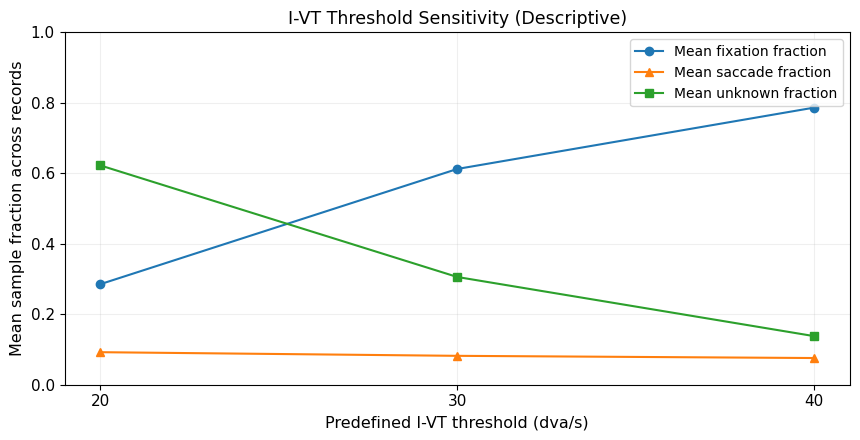

In [ ]:
# ==================== 05. Visualise Threshold Sensitivity ====================

# ------------------ 1. Reuse Saved Classification Fractions ------------------
plot_support = pd.read_csv(output_dir / "06_reference_support.csv")
fig, ax = plt.subplots(figsize=(8.7, 4.5))
threshold = plot_support["threshold_dva_s"]
ax.plot(
    threshold, plot_support["mean_predicted_fixation_fraction"],
    marker="o", label="Mean fixation fraction",
)
ax.plot(
    threshold, plot_support["mean_predicted_saccade_fraction"],
    marker="^", label="Mean saccade fraction",
)
ax.plot(
    threshold, plot_support["mean_unknown_fraction"],
    marker="s", label="Mean unknown fraction",
)
ax.set(
    xlabel="Predefined I-VT threshold (dva/s)",
    ylabel="Mean sample fraction across records",
    ylim=(0, 1), title="I-VT Threshold Sensitivity (Descriptive)",
)
ax.set_xticks([20.0, 30.0, 40.0])
ax.grid(alpha=0.2)
ax.legend(loc="best")
fig.tight_layout()
save_figure(fig, output_dir / "06_threshold_sensitivity.png")
plt.show()


**06. Interpret Sensitivity and Export Current Evidence**

The committed Notebook 06 execution generated and packaged four outputs:

- `06_sensitivity.csv`: **120** record-by-threshold results.
- `06_sensitivity_summary.csv`: **three** unweighted record-mean summaries.
- `06_reference_support.csv`: **three** eligibility, coverage and conditional-agreement summaries; includes the successful 30-dva/s comparison with Notebook 03.
- `06_threshold_sensitivity.png`: the observed fixation, saccade and unknown class-fraction graph.

**Evidence boundary:** The experiment does not identify an optimal threshold, provide expert-ground-truth validation, resolve extreme gaze velocities or establish neurocognitive/clinical performance. Agreement is conditional on recognised vendor labels and threshold-dependent evaluability. The saved CSV outputs are descriptive evidence, not independent replication.

Notebook 07 has subsequently consumed these compatible tables and reported a successful integrated source-identity and summary check. Generated ZIPs and large CSVs remain outside version-controlled output publication by default.


In [8]:
# ============== 06. Document Robustness Boundaries and Download ==============

print("Predefined thresholds:", (20.0, 30.0, 40.0))
print("Detailed source output:", output_dir / "06_sensitivity.csv")
print("Reference denominator support:", output_dir / "06_reference_support.csv")
print("Classification sensitivity plot:", output_dir / "06_threshold_sensitivity.png")
download_outputs_from_colab("eye_tracking_foundations/output", "06")


Predefined thresholds: (20.0, 30.0, 40.0)
Detailed source output: /content/Eye-Tracking-Neurocognitive-Intelligence/eye_tracking_foundations/output/06_sensitivity.csv
Reference denominator support: /content/Eye-Tracking-Neurocognitive-Intelligence/eye_tracking_foundations/output/06_reference_support.csv
Classification sensitivity plot: /content/Eye-Tracking-Neurocognitive-Intelligence/eye_tracking_foundations/output/06_threshold_sensitivity.png
------------------------------------------------------------------------
Notebook 06
Files packaged: 4
  + 06_reference_support.csv
  + 06_sensitivity.csv
  + 06_sensitivity_summary.csv
  + 06_threshold_sensitivity.png
Download ZIP from Colab Contents: /content/eye_tracking_foundations_Notebook_06_Outputs.zip
